# Proyecto 7 - Explorando factores de comportamiento en NovaRetail+


NovaRetail+ es una plataforma de comercio electrónico en Latinoamérica con millones de usuarios.

Para el cierre de 2024, el equipo de **Crecimiento y retención** tiene como objetivo responder:

**¿Qué factores del comportamiento del cliente están más fuertemente asociados con el ingreso anual generado?**

> Este proyecto es un análisis **correlacional** (exploratorio).  
> **Correlación ≠ causalidad.**

## Sección 1 - Cargar y explorar el dataset

En esta sección validamos:
- que el dataset cargue correctamente
- tipos de datos
- valores faltantes / rangos generales

Antes de correlacionar, primero entendemos el “terreno”.

In [1]:
# Importar librerías
# 1. Manipulación y análisis de datos
import pandas as pd
import numpy as np

# 2. Visualización de datos
import matplotlib.pyplot as plt
import seaborn as sns

# 3. Correlaciones y pruebas estadísticas
from scipy.stats import pearsonr, spearmanr
from scipy.stats import pointbiserialr, chi2_contingency


### Cargar Dataset

In [2]:
# Cargar el dataset y explorar datos
df = pd.read_csv("/datasets/novaretail_comportamiento_clientes_2024.csv")
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 15000 entries, 0 to 14999
Data columns (total 12 columns):
 #   Column                     Non-Null Count  Dtype  
---  ------                     --------------  -----  
 0   id_cliente                 15000 non-null  object 
 1   edad                       15000 non-null  float64
 2   nivel_ingreso              15000 non-null  float64
 3   visitas_mes                15000 non-null  int64  
 4   compras_mes                15000 non-null  int64  
 5   gasto_publicidad_dirigida  15000 non-null  float64
 6   satisfaccion               15000 non-null  float64
 7   miembro_premium            15000 non-null  int64  
 8   abandono                   15000 non-null  int64  
 9   tipo_dispositivo           15000 non-null  object 
 10  region                     15000 non-null  object 
 11  ingreso_anual              15000 non-null  float64
dtypes: float64(5), int64(4), object(3)
memory usage: 1.4+ MB


#### Descripción del conjunto de datos

El dataset contiene las siguientes columnas:

- `id_cliente` — Identificador único del cliente.
- `edad` — Edad del cliente.
- `nivel_ingreso` — Ingreso anual estimado del cliente.
- `visitas_mes` — Número de visitas a la aplicación o sitio web durante el mes.
- `compras_mes` — Número de compras realizadas en el mes.
- `gasto_publicidad_dirigida` — Gasto en anuncios asignado al usuario.
- `satisfaccion` — Calificación de satisfacción del cliente en una escala del 1 al 5.
- `miembro_premium` — Indica si el cliente tiene suscripción premium (1) o no (0).
- `abandono` — Indica si el cliente abandonó la plataforma (1) o no (0).
- `tipo_dispositivo` — Tipo de dispositivo utilizado por el cliente (móvil, escritorio o tablet).
- `region` — Región geográfica del cliente (norte, sur, oeste o este).
- `ingreso_anual` — Ingreso anual generado por el cliente para la empresa.

La métrica principal de análisis es `ingreso_anual`, utilizada para evaluar el impacto económico de los clientes.


In [3]:
# mostrar las primeras 5 filas
df.head()

,id_cliente,edad,nivel_ingreso,visitas_mes,compras_mes,gasto_publicidad_dirigida,satisfaccion,miembro_premium,abandono,tipo_dispositivo,region,ingreso_anual
0,CL-100000,44.0,28565.77,9,1,31.36,3.9,0,0,móvil,norte,23.22
1,CL-100001,36.0,29673.44,11,3,24.66,3.7,0,0,tablet,sur,93.47
2,CL-100002,46.0,30642.95,9,0,0.00,2.9,0,0,móvil,este,0.00
3,CL-100003,56.0,39468.61,8,0,6.81,3.1,0,0,móvil,este,0.00
4,CL-100004,35.0,22527.83,9,2,26.49,2.3,0,0,móvil,sur,33.76


## Sección 2 - Preparar datos y documentar supuestos

### Exploración y Limpieza

#### Exploración inicial de los datos
El conjunto de datos contiene **15,000 registros** y **12 columnas**, sin valores nulos.

**Variables numéricas**  
Se identifican las siguientes columnas numéricas:
- `edad`
- `nivel_ingreso`
- `visitas_mes`
- `compras_mes`
- `gasto_publicidad_dirigida`
- `satisfaccion`
- `ingreso_anual`

La mayoría de estas variables presentan tipos de datos adecuados.  
La columna `edad` está almacenada como `float64`. Dado que representa la edad en años, se revisará si sus valores son enteros antes de convertirla a `int64`.


**Variables binarias**  
Las siguientes columnas representan variables binarias:
- `miembro_premium`
- `abandono`

Ambas están codificadas como 0 y 1, **no requieren transformación adicional**.

**Variables categóricas**  
Se identifican las siguientes columnas categóricas:
- `id_cliente`
- `tipo_dispositivo`
- `region`

Estas variables están correctamente definidas y no requieren transformación adicional.

In [4]:
# Verificar si existen edades con decimales
(df["edad"] % 1 != 0).sum()

0

In [5]:
# Corregir el tipo de dato de columna edad
df["edad"] = df["edad"].astype(int)

In [6]:
# verificar cambios
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 15000 entries, 0 to 14999
Data columns (total 12 columns):
 #   Column                     Non-Null Count  Dtype  
---  ------                     --------------  -----  
 0   id_cliente                 15000 non-null  object 
 1   edad                       15000 non-null  int64  
 2   nivel_ingreso              15000 non-null  float64
 3   visitas_mes                15000 non-null  int64  
 4   compras_mes                15000 non-null  int64  
 5   gasto_publicidad_dirigida  15000 non-null  float64
 6   satisfaccion               15000 non-null  float64
 7   miembro_premium            15000 non-null  int64  
 8   abandono                   15000 non-null  int64  
 9   tipo_dispositivo           15000 non-null  object 
 10  region                     15000 non-null  object 
 11  ingreso_anual              15000 non-null  float64
dtypes: float64(4), int64(5), object(3)
memory usage: 1.4+ MB


La columna `edad` se encontraba inicialmente almacenada como `float64`. Se verificó que ninguno de sus 15.000 registros contenía valores decimales, por lo que se convirtió a `int64` mediante `.astype(int)`.

Posteriormente, se confirmó con `df.info()` que la transformación fue exitosa, conservando los 15.000 registros y las 12 columnas originales.

#### Explorar variables numéricas

In [7]:
# Estadísticas descriptivas de variables numéricas
df.describe()

,edad,nivel_ingreso,visitas_mes,compras_mes,gasto_publicidad_dirigida,satisfaccion,miembro_premium,abandono,ingreso_anual
count,15000.000000,15000.000000,15000.000000,15000.000000,15000.000000,15000.000000,15000.000000,15000.000000,15000.000000
mean,38.262400,30019.704782,10.029000,1.206467,20.149301,3.603693,0.139267,0.150733,36.594180
std,11.492378,9833.166305,3.158189,1.105284,10.880724,0.685300,0.346236,0.357801,34.484888
min,18.000000,8000.000000,1.000000,0.000000,0.000000,1.000000,0.000000,0.000000,0.000000
25%,30.000000,23127.097500,8.000000,0.000000,12.310000,3.100000,0.000000,0.000000,0.000000
50%,38.000000,30023.745000,10.000000,1.000000,19.730000,3.600000,0.000000,0.000000,30.705000
75%,46.000000,36768.440000,12.000000,2.000000,27.292500,4.100000,0.000000,0.000000,58.220000
max,75.000000,74790.840000,25.000000,8.000000,75.510000,5.000000,1.000000,1.000000,244.690000



### Diagnóstico inicial de variables numéricas

- `edad` Los clientes tienen edades entre 18 y 75 años, con una media de 38,26 años y una mediana de 38. Los valores observados se encuentran dentro de un rango plausible para clientes adultos.
- `nivel_ingreso`: El ingreso anual estimado presenta una media de 30.019,70 y una mediana de 30.023,75. Ambos valores son muy cercanos, aunque existe una dispersión considerable entre el mínimo de 8.000 y el máximo de 74.790,84.
- `visitas_mes`: Los clientes realizan en promedio 10,03 visitas mensuales. La mediana es de 10 y los valores oscilan entre 1 y 25 visitas.
- `compras_mes`: Se registra un promedio de 1,21 compras mensuales y una mediana de 1. El primer cuartil es 0, lo que evidencia que al menos el 25 % de los clientes no realizó compras durante el mes.
- `gasto_publicidad_dirigida`: El gasto promedio en publicidad por cliente es de 20,15, con valores entre 0 y 75,51. La media supera ligeramente la mediana de 19,73, por lo que conviene explorar su distribución.
- `satisfaccion`: La satisfacción promedio es de 3,60 sobre una escala de 1 a 5. La mediana es 3,6, con valores dentro del rango esperado
- `miembro_premium`: Es una variable binaria con valores de 0 y 1. Su media de 0,1393 indica que aproximadamente el 13,93 % de los clientes pertenece al programa premium.
- `abandono`: Es una variable binaria con valores de 0 y 1. Su media de 0,1507 indica que aproximadamente el 15,07 % de los clientes está registrado como usuario que abandonó la plataforma.
- `ingreso_anual`: Es la variable objetivo. Presenta una media de 36,59 y una mediana de 30,71, con valores entre 0 y 244,69. La diferencia entre media y mediana sugiere una posible asimetría positiva, que deberá confirmarse mediante visualizaciones.

**Conclusión preliminar**: Las estadísticas descriptivas no muestran valores mínimos o máximos evidentemente incompatibles con las definiciones de las variables. Sin embargo, será necesario complementar esta revisión con el análisis de distribuciones, valores atípicos y consistencia de los datos.

#### Explorar variables binarias

In [8]:
# Verificar que cada columna tenga únicamente dos valores posibles
print("Miembro premium:", df["miembro_premium"].unique())
print("Abandono:", df["abandono"].unique())

Miembro premium: [0 1]
Abandono: [0 1]


### Diagnóstico inicial de variables binarias

- `miembro_premium`: Se verificó que la variable contiene únicamente los valores 0 y 1, donde 0 representa a los clientes sin suscripción premium y 1 a los clientes suscritos. No requiere transformación adicional. Según las estadísticas descriptivas, aproximadamente el 13,93 % de los clientes pertenece al programa premium. 
- `abandono`: Se confirmó que la variable contiene exclusivamente los valores 0 y 1, donde 0 representa a los clientes que no abandonaron la plataforma y 1 a quienes sí la abandonaron. No requiere transformación adicional. Aproximadamente el 15,07 % de los clientes registra abandono.

**Conclusión**: Ambas variables binarias presentan una codificación adecuada para realizar posteriormente análisis de correlación punto-biserial con la variable objetivo `ingreso_anual`.

#### Explorar variables categóricas

In [9]:
# Verificar el número de valores únicos por variable categórica
print("Tipo de dispositivo:", df["tipo_dispositivo"].nunique())
print("Región:", df["region"].nunique())

Tipo de dispositivo: 3
Región: 4


In [10]:
# Explorar variables categóricas y cómo se distribuyen
print("Distribución por dispositivo:")
print(df["tipo_dispositivo"].value_counts())

print("\nDistribución por región:")
print(df["region"].value_counts())

Distribución por dispositivo:
móvil         9818
escritorio    3720
tablet        1462
Name: tipo_dispositivo, dtype: int64

Distribución por región:
norte    4395
oeste    3810
sur      3726
este     3069
Name: region, dtype: int64



### Diagnóstico inicial de variables categóricas

- `tipo_dispositivo`: Se identificaron tres categorías: móvil, escritorio y tablet. El dispositivo móvil presenta la mayor participación, con 9.818 clientes (65,45 %), seguido de escritorio con 3.720 (24,80 %) y tablet con 1.462 (9,75 %). Esto evidencia un predominio del uso de dispositivos móviles entre los clientes registrados.
- `region`: Se identificaron cuatro categorías: norte, oeste, sur y este. La región norte concentra la mayor proporción de clientes, con 4.395 registros (29,30 %), mientras que la región este presenta la menor, con 3.069 (20,46 %). Las regiones oeste y sur tienen participaciones relativamente similares.

**Conclusión preliminar**: Las variables categóricas presentan las categorías esperadas según el diccionario de datos y no se observan inconsistencias en sus nombres. Por lo tanto, no requieren transformación adicional para esta etapa del análisis.

Posteriormente, se podrán analizar posibles diferencias en el comportamiento y los ingresos generados según el dispositivo utilizado y la región geográfica.

### Supuestos

- El análisis se realiza utilizando **todo el conjunto de datos disponible**.
- Los datos no presentan errores y están correctamente tipificados.
- Se utilizan distintos coeficientes según el tipo de variable:
  - **Pearson** asume relaciones lineales entre variables numéricas.
  - **Spearman** evalúa relaciones monótonas y no requiere normalidad.
  - **Punto biserial** se usa para relaciones numérica–binaria.
  - **Cramér (V)** se usa para asociaciones entre variables categóricas.

**Supuesto central:**  
Este análisis identifica relaciones entre variables o segmentos, pero no prueba causalidad.

## Sección 3 - Visualización de relaciones

Observamos cómo se relacionan las variables numéricas.

### Heatmap

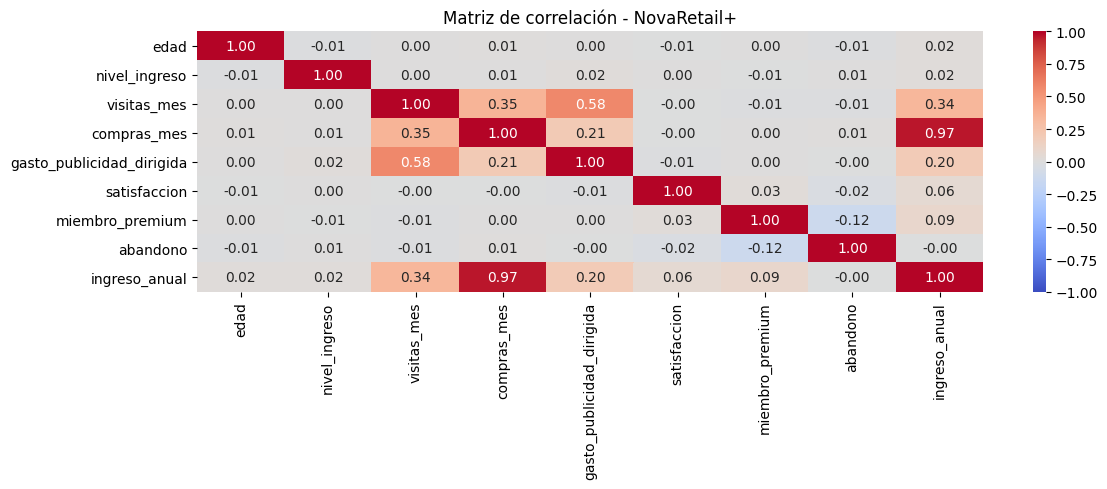

In [11]:
# Visualizar la matriz de correlación para identificar relaciones
# Seleccionar variables numéricas
columnas_numericas = df.select_dtypes(include=["number"])

# Calcular matriz de correlación de Pearson
matriz_corr = columnas_numericas.corr(method="pearson")

# Crear heatmap
plt.figure(figsize=(12, 5))

sns.heatmap(
    matriz_corr,
    annot=True,
    cmap="coolwarm",
    fmt=".2f",
    vmin=-1,
    vmax=1,
    center=0
)

plt.title("Matriz de correlación - NovaRetail+")
plt.tight_layout()
plt.show()

### Observaciones generales (Heatmap)  

La matriz de correlación de Pearson permitió identificar las principales asociaciones lineales entre las variables numéricas del dataset.
- Se observa una correlación positiva muy fuerte entre `compras_mes` e `ingreso_anual` (r = 0,97), lo que indica que los clientes con mayor frecuencia de compras tienden a generar mayores ingresos.
- `visitas_mes` y `gasto_publicidad_dirigida` presentan una correlación positiva moderada (r = 0,58).
- La relación entre `visitas_mes` y `compras_mes` es positiva, de intensidad débil a moderada (r = 0,35).
- `miembro_premium` y `abandono` presentan una correlación negativa débil (r = -0,12).
- Las demás relaciones presentan, en general, asociaciones lineales débiles o cercanas a cero.

Observaciones respecto a `ingreso_anual`  
- `compras_mes`: presenta la asociación positiva más fuerte con el ingreso anual (r = 0,97).
- `visitas_mes`: muestra una asociación positiva débil a moderada (r = 0,34).
- `gasto_publicidad_dirigida`: presenta una relación positiva débil (r = 0,20).
- `miembro_premium`: presenta una asociación positiva muy débil (r = 0,09).
- `satisfaccion`, `edad` y `nivel_ingreso`: presentan correlaciones positivas muy débiles o prácticamente nulas.
- `abandono`: presenta una correlación prácticamente nula con el ingreso anual.

**Conclusión preliminar**: La frecuencia de compras mensuales es el factor con mayor asociación lineal con los ingresos anuales generados por los clientes. Sin embargo, estas correlaciones no permiten establecer relaciones de causa y efecto. Será necesario complementar los resultados mediante visualizaciones adicionales y otros coeficientes de correlación.


### Scatterplot general

Con base en los resultados del análisis de correlación, evalúa si es necesario generar un *scatterplot* general.

- **Si decides incluirlo**:
  - Genera el gráfico.
  - Describe brevemente qué patrones o tendencias observas.

- **Si decides no incluirlo**:
  - Explica por qué.

Se decidió **no incluir** un scatterplot general, dado que el heatmap permitió identificar las principales asociaciones lineales entre las variables numéricas.

En su lugar, se realizarán scatterplots específicos en la sección 3.3 para examinar con mayor detalle los pares de variables que presentan correlaciones moderadas o fuertes.

Esta decisión permite evitar visualizaciones redundantes y facilita la interpretación de tendencias, dispersión y posibles valores atípicos.

### Scatterplot para pares clave

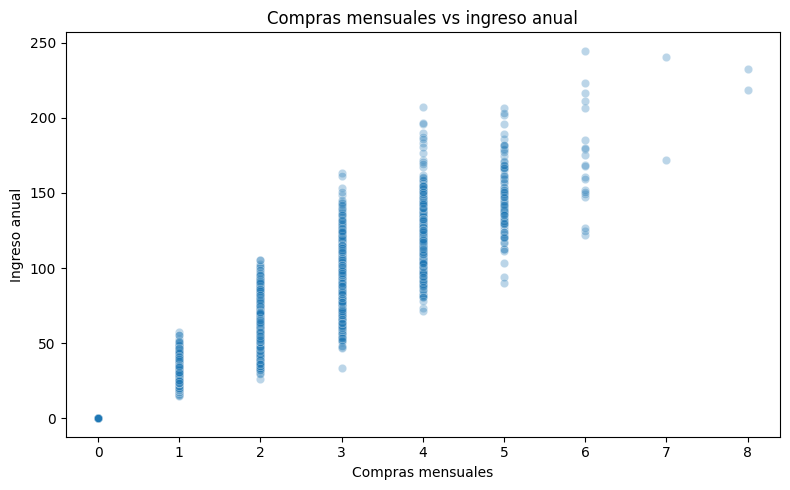

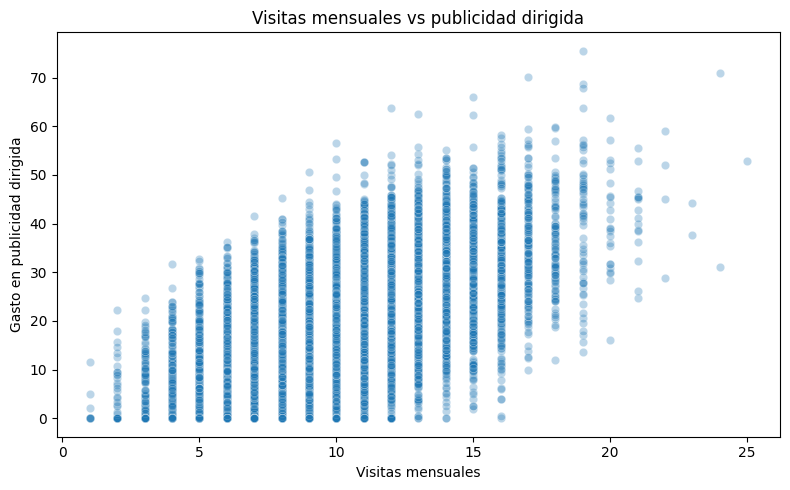

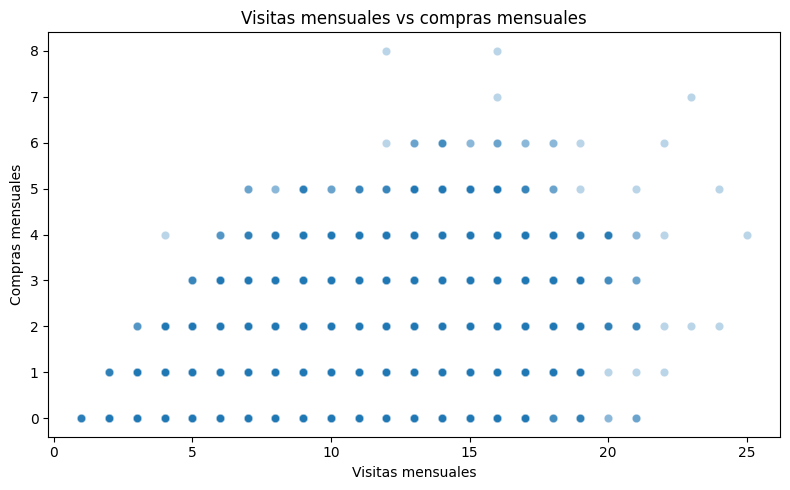

In [12]:
# Visualizar pares de variables con relaciones moderadas o fuertes
# Scatterplot 1: Compras mensuales vs ingreso anual
plt.figure(figsize=(8, 5))

sns.scatterplot(
    data=df,
    x="compras_mes",
    y="ingreso_anual",
    alpha=0.3
)

plt.title("Compras mensuales vs ingreso anual")
plt.xlabel("Compras mensuales")
plt.ylabel("Ingreso anual")
plt.tight_layout()
plt.show()


# Scatterplot 2: Visitas vs publicidad dirigida
plt.figure(figsize=(8, 5))

sns.scatterplot(
    data=df,
    x="visitas_mes",
    y="gasto_publicidad_dirigida",
    alpha=0.3
)

plt.title("Visitas mensuales vs publicidad dirigida")
plt.xlabel("Visitas mensuales")
plt.ylabel("Gasto en publicidad dirigida")
plt.tight_layout()
plt.show()


# Scatterplot 3: Visitas vs compras
plt.figure(figsize=(8, 5))

sns.scatterplot(
    data=df,
    x="visitas_mes",
    y="compras_mes",
    alpha=0.3
)

plt.title("Visitas mensuales vs compras mensuales")
plt.xlabel("Visitas mensuales")
plt.ylabel("Compras mensuales")
plt.tight_layout()
plt.show()

### Observaciones iniciales (Scatterplot)

**compras_mes vs. ingreso_anual**
- Dirección positiva muy fuerte (r = 0,97).
- Dispersión: relativamente baja alrededor de la tendencia ascendente, aunque existe variabilidad en los ingresos para cada cantidad de compras.
- Posibles outliers: se observan valores de ingresos elevados que requieren verificación antes de considerarse atípicos.
- Posible colinealidad: Se observa una correlación positiva muy fuerte (r = 0,97) entre compras_mes e ingreso_anual. Sin embargo, esta relación no constituye por sí sola evidencia de multicolinealidad, ya que ingreso_anual es la variable objetivo.

**visitas_mes vs. gasto_publicidad_dirigida**
- Dirección positiva moderada (r = 0,58).
- Dispersión: media-alta, con variabilidad considerable en el gasto publicitario para cantidades similares de visitas.
- Posibles outliers: se identifican visualmente algunos gastos publicitarios elevados que conviene analizar.
- Posible colinealidad: existe una asociación moderada entre estas variables explicativas.

**visitas_mes vs. compras_mes**
- Dirección: positiva débil a moderada (r = 0,35).
- Dispersión: alta. Los clientes con cantidades similares de visitas pueden realizar diferentes números de compras.
- Posibles outliers: se observan pocos registros con siete u ocho compras mensuales, que podrían requerir revisión.
- Posible colinealidad: la asociación encontrada es relativamente baja y no demuestra multicolinealidad problemática.

**Conclusión general**

Los scatterplots respaldan visualmente las asociaciones identificadas mediante el heatmap. La relación más fuerte corresponde a compras_mes e ingreso_anual, mientras que las demás presentan una dispersión mayor.

No se observan evidencias visuales suficientes para afirmar que existan errores en los datos o problemas graves de multicolinealidad. Sin embargo, estas posibilidades no pueden descartarse únicamente a partir de los gráficos.

Los patrones observados se complementan con los coeficientes de Pearson y Spearman presentados en la sección 4, que permiten comparar la dirección y magnitud de las asociaciones.

## Sección 4 - Coeficientes de correlación y evidencia numérica

En esta sección, se reportan coeficientes que respaldan los patrones
observados visualmente, utilizando el método adecuado según el tipo
de variables.

### Pearson / Spearman

In [13]:
# Calcular correlación entre variables relevantes
# Seleccionar variables numéricas relevantes
columnas_numericas = [
    "visitas_mes",
    "compras_mes",
    "gasto_publicidad_dirigida",
    "satisfaccion",
    "edad",
    "nivel_ingreso",
    "ingreso_anual"
]

# Función para calcular correlaciones
def corr_numerica(df, columnas, metodo="pearson"):
    return df[columnas].corr(method=metodo)

# Calcular correlación de Pearson
correlacion_pearson = corr_numerica(
    df, columnas_numericas, metodo="pearson"
)

correlacion_pearson.round(3)

,visitas_mes,compras_mes,gasto_publicidad_dirigida,satisfaccion,edad,nivel_ingreso,ingreso_anual
visitas_mes,1.000,0.354,0.579,-0.003,0.005,0.001,0.337
compras_mes,0.354,1.000,0.208,-0.004,0.015,0.007,0.967
gasto_publicidad_dirigida,0.579,0.208,1.000,-0.013,0.000,0.017,0.197
satisfaccion,-0.003,-0.004,-0.013,1.000,-0.007,0.002,0.056
edad,0.005,0.015,0.000,-0.007,1.000,-0.009,0.017
nivel_ingreso,0.001,0.007,0.017,0.002,-0.009,1.000,0.017
ingreso_anual,0.337,0.967,0.197,0.056,0.017,0.017,1.000


In [14]:
# Calcular correlación entre variables relevantes
# Calcular correlación de Spearman
correlacion_spearman = corr_numerica(
    df, columnas_numericas, metodo="spearman"
)

correlacion_spearman.round(3)

,visitas_mes,compras_mes,gasto_publicidad_dirigida,satisfaccion,edad,nivel_ingreso,ingreso_anual
visitas_mes,1.000,0.333,0.559,-0.001,0.005,0.001,0.321
compras_mes,0.333,1.000,0.193,-0.002,0.016,0.009,0.967
gasto_publicidad_dirigida,0.559,0.193,1.000,-0.013,0.003,0.015,0.185
satisfaccion,-0.001,-0.002,-0.013,1.000,-0.008,0.005,0.061
edad,0.005,0.016,0.003,-0.008,1.000,-0.008,0.016
nivel_ingreso,0.001,0.009,0.015,0.005,-0.008,1.000,0.025
ingreso_anual,0.321,0.967,0.185,0.061,0.016,0.025,1.000


### Observaciones de correlación Pearson / Spearman

**compras_mes vs. ingreso_anual**
- Correlación: Pearson = 0,967 y Spearman = 0,967.
- Dirección: positiva.
- Magnitud: muy fuerte. Los clientes que realizan más compras mensuales tienden a generar mayores ingresos anuales.
- Posible colinealidad: los coeficientes son prácticamente idénticos, lo que evidencia una asociación fuerte y consistente entre ambos métodos. Sin embargo, no constituye por sí sola multicolinealidad, porque ingreso_anual es la variable objetivo.

**visitas_mes vs. gasto_publicidad_dirigida**
- Correlación: Pearson = 0,579 y Spearman = 0,559.
- Dirección: positiva.
- Magnitud: moderada. Los clientes con mayor número de visitas tienden a registrar mayor gasto en publicidad dirigida.
- Posible colinealidad: existe una asociación moderada entre estas dos variables explicativas. La similitud entre ambos coeficientes muestra consistencia, aunque no confirma multicolinealidad problemática.

**visitas_mes vs. compras_mes**
- Correlación: Pearson = 0,354 y Spearman = 0,333.
- Dirección: positiva.
- Magnitud: débil a moderada. Los clientes que visitan más veces la plataforma tienden a realizar más compras.
- Posible colinealidad: la asociación entre estas variables explicativas es relativamente baja, por lo que no se observa una colinealidad fuerte.

**visitas_mes vs. ingreso_anual**
- Correlación: Pearson = 0,337 y Spearman = 0,321.
- Dirección: positiva.
- Magnitud: débil a moderada. Los clientes con mayor frecuencia de visitas tienden a generar mayores ingresos anuales.
- Posible colinealidad: la relación incluye la variable objetivo, por lo que no constituye evidencia directa de multicolinealidad.

**gasto_publicidad_dirigida vs. ingreso_anual**
- Correlación: Pearson = 0,197 y Spearman = 0,185.
- Dirección: positiva.
- Magnitud: débil. Existe una asociación positiva de baja intensidad entre la publicidad dirigida y los ingresos generados.
- Posible colinealidad: no puede diagnosticarse multicolinealidad a partir de este par porque incluye la variable objetivo.

**Conclusión general**

Se calcularon las matrices de correlación de Pearson y Spearman para las siete variables numéricas seleccionadas. Para la interpretación detallada se priorizaron los pares con asociaciones más relevantes, especialmente aquellos relacionados con la variable objetivo ingreso_anual, así como las relaciones entre variables explicativas.

Los coeficientes de Pearson y Spearman presentan resultados similares en dirección y magnitud, lo que respalda la consistencia de las asociaciones observadas.
La relación más fuerte corresponde a `compras_mes` e `ingreso_anual`, con un coeficiente de 0,967 en ambos métodos.
Entre las variables explicativas, la asociación más destacada es la de `visitas_mes` y `gasto_publicidad_dirigida`, con coeficientes de 0,579 y 0,559, respectivamente.

### Punto-biserial

In [20]:
# Calcular correlación entre variables relevantes
# Función de correlación punto-biserial
def corr_point_biserial(df, col_binaria, columnas_numericas):
    for col in columnas_numericas:
        coef, _ = pointbiserialr(df[col_binaria], df[col])

        print(f"\nCorrelación entre: {col_binaria} y {col}")
        print(f"Point-Biserial: {coef:.4f}")


# Seleccionar variables numéricas relevantes
columnas_numericas_pb = [
    "visitas_mes",
    "compras_mes",
    "gasto_publicidad_dirigida",
    "satisfaccion",
    "ingreso_anual"
]

# Calcular correlaciones para miembro premium
corr_point_biserial(df, "miembro_premium", columnas_numericas_pb)

# Calcular correlaciones para abandono
corr_point_biserial(df, "abandono", columnas_numericas_pb)


Correlación entre: miembro_premium y visitas_mes
Point-Biserial: -0.0127

Correlación entre: miembro_premium y compras_mes
Point-Biserial: 0.0034

Correlación entre: miembro_premium y gasto_publicidad_dirigida
Point-Biserial: 0.0027

Correlación entre: miembro_premium y satisfaccion
Point-Biserial: 0.0257

Correlación entre: miembro_premium y ingreso_anual
Point-Biserial: 0.0931

Correlación entre: abandono y visitas_mes
Point-Biserial: -0.0089

Correlación entre: abandono y compras_mes
Point-Biserial: 0.0083

Correlación entre: abandono y gasto_publicidad_dirigida
Point-Biserial: -0.0046

Correlación entre: abandono y satisfaccion
Point-Biserial: -0.0238

Correlación entre: abandono y ingreso_anual
Point-Biserial: -0.0028



### Observaciones Punto-biserial

**1. miembro_premium vs. ingreso_anual**
- Relación: positiva muy débil (r = 0,0931).
- Dirección: positiva. Los clientes premium (1) presentan ingresos promedio superiores a los no premium (0), aunque la asociación entre ambas variables es muy débil.
- Magnitud: muy débil, ya que el coeficiente está cercano a cero.
- Interpretación: pertenecer al programa premium presenta una asociación positiva de baja intensidad con el ingreso anual generado. No se puede concluir que la suscripción premium provoque un aumento de ingresos.

**2. abandono vs. ingreso_anual**
- Relación: negativa prácticamente nula (r = -0,0028).
- Dirección: negativa. Los clientes que abandonaron la plataforma (1) presentan ingresos promedio apenas inferiores a quienes no abandonaron (0).
- Magnitud: prácticamente nula, debido a que el coeficiente es extremadamente cercano a cero.
- Interpretación: no se observa una asociación lineal relevante entre el abandono de la plataforma y el ingreso anual generado.

**Conclusión general**

Se calcularon diez correlaciones punto-biseriales para analizar la relación de las variables binarias miembro_premium y abandono con cinco variables numéricas de comportamiento e ingresos.

Todas las asociaciones presentan magnitudes muy débiles o prácticamente nulas.
La relación más destacada corresponde a miembro_premium e ingreso_anual (r = 0,0931), aunque su intensidad sigue siendo muy baja.
Por tanto, las variables binarias analizadas presentan asociaciones considerablemente menores con los ingresos anuales que compras_mes, cuya correlación de Pearson fue 0,967.
Estos resultados son exploratorios y no permiten establecer causalidad.

### V de Cramér

In [18]:
# Función para calcular V de Cramér
def cramers_v(df, col1, col2):
    tabla = pd.crosstab(df[col1], df[col2])

    chi2, _, _, _ = chi2_contingency(tabla)

    n = tabla.to_numpy().sum()
    filas, columnas = tabla.shape

    v = np.sqrt(chi2 / (n * (min(filas, columnas) - 1)))

    return v

In [19]:
# Aplicar V de Cramér en variables relevantes
pares_categoricos = [
    ("tipo_dispositivo", "region"),
    ("tipo_dispositivo", "miembro_premium"),
    ("region", "abandono"),
    ("miembro_premium", "abandono")
]

# Calcular V de Cramér
for col1, col2 in pares_categoricos:
    v = cramers_v(df, col1, col2)
    print(f"{col1} vs {col2}: V de Cramér = {v:.4f}")


tipo_dispositivo vs region: V de Cramér = 0.0124
tipo_dispositivo vs miembro_premium: V de Cramér = 0.0197
region vs abandono: V de Cramér = 0.0154
miembro_premium vs abandono: V de Cramér = 0.1202


### Observaciones V de Cramér

**1. tipo_dispositivo vs. region**
- Relación: prácticamente nula (V = 0,0124).
- Interpretación: no se identifica una asociación relevante entre el tipo de dispositivo utilizado y la región geográfica de los clientes.

**2. tipo_dispositivo vs. miembro_premium**
- Relación: prácticamente nula (V = 0,0197).
- Interpretación: el tipo de dispositivo utilizado presenta una asociación prácticamente inexistente con la pertenencia al programa premium.

**3. region vs. abandono**
- Relación: prácticamente nula (V = 0,0154).
- Interpretación: no se observa una asociación relevante entre la región geográfica y el abandono de la plataforma.

**4. miembro_premium vs. abandono**
- Relación: débil (V = 0,1202).
- Interpretación: se identifica una asociación débil entre pertenecer al programa premium y abandonar la plataforma. Sin embargo, V de Cramér no permite determinar la dirección de esta relación.

**Conclusión general**

Se calcularon cuatro coeficientes V de Cramér para evaluar asociaciones entre variables categóricas y binarias.
Tres de las cuatro relaciones presentan coeficientes muy cercanos a cero, lo que indica asociaciones prácticamente nulas.
La asociación más destacada corresponde a miembro_premium y abandono (V = 0,1202), aunque su intensidad sigue siendo débil.
Estos resultados sugieren que las relaciones categóricas analizadas tienen una intensidad limitada. No permiten establecer causalidad y deben interpretarse dentro del contexto exploratorio del proyecto.


## Sección 5 - Interpretación de resultados para el negocio

Cada hallazgo  debe incluir:
1) Evidencia visual (si aplica)
2) Evidencia numérica  
3) Interpretación (no causal)  
4) No podemos afirmar
5) Implicación de negocio

---

### Hallazgo 1 — Las compras mensuales presentan la asociación más fuerte con los ingresos anuales

**Evidencia visual:**   
El heatmap y el scatterplot muestran una tendencia positiva muy marcada entre `compras_mes` e `ingreso_anual`. A medida que aumenta la cantidad de compras mensuales, los ingresos generados tienden a ser mayores.

**Evidencia numérica:** 
- Pearson: r = 0,967.
- Spearman: ρ = 0,967.
Ambos coeficientes indican una asociación positiva muy fuerte y consistente entre los dos métodos.

**Interpretación**  
Los clientes que realizan más compras mensuales tienden a generar mayores ingresos anuales para NovaRetail+. Esta es la asociación de mayor magnitud identificada con la variable objetivo.

**No podemos afirmar**  
No podemos concluir que una intervención para incrementar la frecuencia de compras producirá necesariamente un aumento proporcional en los ingresos. La relación observada es correlacional y no demuestra causalidad.

**Implicación de negocio**  
La frecuencia de compras mensuales puede utilizarse como un indicador relevante para identificar y segmentar clientes según su actividad comercial y los ingresos que generan para NovaRetail+.

Se recomienda investigar estrategias de recompra y fidelización, especialmente dirigidas a clientes con baja frecuencia de compras, y evaluar su efectividad mediante pruebas controladas antes de implementarlas a gran escala.

### Hallazgo 2 — Las visitas mensuales presentan una asociación positiva con los ingresos 

**Evidencia visual:**   
El heatmap muestra una asociación positiva entre `visitas_mes` e `ingreso_anual` (r = 0,337). Adicionalmente, el scatterplot de `visitas_mes` frente a `compras_mes` presenta una tendencia ascendente con dispersión considerable, lo que permite observar que una mayor frecuencia de visitas no siempre está acompañada de un mayor número de compras.

**Evidencia numérica:** 
- Pearson: r = 0,337.
- Spearman: ρ = 0,321.

**Interpretación**  
Los clientes que visitan la plataforma con mayor frecuencia tienden a generar mayores ingresos anuales. Sin embargo, esta asociación es considerablemente más débil que la observada entre compras e ingresos.

**No podemos afirmar**  
No se puede concluir que aumentar las visitas genere automáticamente mayores ingresos o más compras.

**Implicación de negocio**  
Se recomienda analizar la conversión de visitas en compras e investigar posibles barreras durante el proceso de compra. Esto permitiría identificar oportunidades para mejorar la experiencia del cliente.


### Hallazgo 3 — La publicidad dirigida presenta una asociación positiva débil con los ingresos

**Evidencia visual**:
El heatmap muestra una asociación positiva débil entre `gasto_publicidad_dirigida` e `ingreso_anual`. Adicionalmente, el scatterplot de publicidad dirigida frente a visitas mensuales muestra una tendencia positiva moderada, con dispersión considerable.

**Evidencia numérica**:
- Publicidad dirigida e ingreso anual: Pearson = 0,197; Spearman = 0,185.
- Visitas mensuales y publicidad dirigida: Pearson = 0,579; Spearman = 0,559.

**Interpretación**:
Se observa una asociación positiva débil entre `gasto_publicidad_dirigida` e `ingreso_anual`. Esto indica que los clientes con mayor gasto publicitario asignado tienden a generar mayores ingresos, aunque la relación es de baja intensidad. Adicionalmente, existe una asociación positiva moderada entre la publicidad dirigida y la frecuencia de visitas.

**No podemos afirmar**:
No podemos concluir que aumentar la inversión publicitaria cause mayores ingresos o más visitas, ni que las campañas sean rentables únicamente por presentar correlaciones positivas.

**Implicación de negocio**:
Se recomienda evaluar la efectividad de las campañas publicitarias mediante métricas de conversión, costos e ingresos generados, y realizar pruebas controladas antes de aumentar la inversión.

### Hallazgo 4 — La suscripción premium presenta una asociación muy débil con los ingresos

**Evidencia visual**:
El heatmap muestra una asociación positiva muy débil entre miembro_premium e ingreso_anual.

**Evidencia numérica**:
Correlación punto-biserial: r = 0,0931.

**Interpretación**:
Los clientes premium presentan ingresos promedio superiores a los no premium. Sin embargo, la magnitud de la asociación es muy débil, por lo que pertenecer al programa premium no permite explicar por sí solo las diferencias de ingresos entre los clientes.

**No podemos afirmar**:
No podemos concluir que adquirir una membresía premium provoque un aumento de ingresos ni que el programa sea rentable únicamente a partir de esta correlación.

**Implicación de negocio**:
Se recomienda evaluar el desempeño del programa premium mediante comparaciones segmentadas de ingresos, frecuencia de compras y retención, considerando también los costos y beneficios asociados a la membresía.

## Sección 6 - Limitaciones y próximos pasos

### **Limitaciones**
- Correlación ≠ causalidad: Las asociaciones identificadas no demuestran que una variable provoque cambios en otra. Por ejemplo, la relación entre compras_mes e ingreso_anual (r = 0,967) no permite asegurar que una intervención para aumentar las compras produzca necesariamente un incremento proporcional en los ingresos.
  
- Datos de un solo período: El análisis corresponde a información de 2024, por lo que no permite determinar si las relaciones observadas se mantienen a lo largo del tiempo.

- Posibles variables no consideradas: Factores como promociones, descuentos, categorías de productos, precios y antigüedad del cliente podrían influir en el comportamiento de compra y los ingresos, pero no están incluidos en el dataset.

- Valores atípicos: Se observaron algunos valores elevados en las visualizaciones. Sin embargo, no se realizó una evaluación formal de outliers, por lo que no podemos descartar su influencia en los coeficientes.

- Limitaciones de las correlaciones: Pearson mide asociaciones lineales, Spearman relaciones monótonas, punto-biserial asociaciones entre variables binarias y numéricas, y V de Cramér asociaciones categóricas. Ninguno de estos métodos permite explicar por sí solo todos los factores que determinan los ingresos.

- Calidad de los datos: Aunque se verificaron los tipos de datos, la ausencia de nulos y las categorías principales, no se completaron todas las validaciones posibles, como la revisión de duplicados y consistencia de registros, solamente se supuso su validación. 

### **Próximos pasos** 

**Paso 1. Probar segmentación adicional**
- Analizar los ingresos promedio y la frecuencia de compras por region y tipo_dispositivo para identificar diferencias entre segmentos.
- Comparar el comportamiento de los clientes premium y no premium, así como de quienes abandonaron la plataforma y quienes permanecieron.
- Evaluar si las asociaciones observadas en el conjunto general cambian al segmentar los datos, considerando posibles efectos de composición o paradojas de Simpson.

**Paso 2. Profundizar en la calidad y distribución de los datos**
- Identificar y revisar posibles valores atípicos en ingreso_anual, compras_mes y gasto_publicidad_dirigida, sin eliminarlos automáticamente.
- Verificar registros duplicados y otras inconsistencias que puedan afectar la confiabilidad del análisis.
- Complementar las correlaciones con visualizaciones de distribuciones y comparaciones de promedios por segmento.

**Paso 3. Evaluar oportunidades de crecimiento y retención**
- Investigar estrategias que puedan favorecer la recompra y mejorar la conversión de visitas en compras.
- Evaluar la efectividad de las campañas de publicidad dirigida y del programa premium mediante indicadores de desempeño y rentabilidad.
- Diseñar experimentos controlados para comprobar si las acciones propuestas generan mejoras reales en ingresos y retención.